# EDA

In [1]:
## Laoding Processes Datasets

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

# Load raw datasets
root_dir = Path.cwd().parent
data_dir = root_dir / "data" / "processed"

campaigns = pd.read_csv(data_dir / "campaigns.csv")
customer_summary = pd.read_csv(data_dir / "customer_summary.csv")
sessions = pd.read_csv(data_dir/ "website_sessions.csv")
customers = pd.read_csv(data_dir / "customers.csv")
events = pd.read_csv(data_dir / "website_events.csv")
orders = pd.read_csv(data_dir / "orders.csv")
marketing_spend = pd.read_csv(data_dir / "marketing_spend.csv")

print("All datasets loaded successfully.")



All datasets loaded successfully.


In [2]:
datasets = {
    "campaigns": campaigns,
    "customers": customers,
    "customers": customer_summary,
    "sessions": sessions,
    "events": events,
    "orders": orders,
    "marketing_spend": marketing_spend
}

In [3]:

for name,df in datasets.items():
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns ")

campaigns: 19 rows, 5 columns 
customers: 3302 rows, 11 columns 
sessions: 45000 rows, 14 columns 
events: 144097 rows, 6 columns 
orders: 4278 rows, 11 columns 
marketing_spend: 6552 rows, 8 columns 


In [4]:
for name, df in datasets.items(): 
    print(f"\n{'='*50}")
    print(f"  TABLE: {name}")
    print(f"{'='*50}")
    print(f"\n ## Data Types & Missing Values:\n")

    inspection = pd.DataFrame({
        'dtype':df.dtypes,
        'Missing_Count': df.isnull().sum(), 
        'Missing_Pct' : (df.isnull().sum()/len(df)*100).round(2),
        'Duplicate rows' : (df.duplicated().sum())
    })

    print(inspection)



  TABLE: campaigns

 ## Data Types & Missing Values:

                        dtype  Missing_Count  Missing_Pct  Duplicate rows
campaign_id               str              0          0.0               0
campaign_name             str              0          0.0               0
channel                   str              0          0.0               0
campaign_type             str              0          0.0               0
cost_tracking_available  bool              0          0.0               0

  TABLE: customers

 ## Data Types & Missing Values:

                        dtype  Missing_Count  Missing_Pct  Duplicate rows
customer_id               str              0         0.00               0
first_purchase_date       str              0         0.00               0
total_orders            int64              0         0.00               0
total_revenue         float64              0         0.00               0
repeat_customer          bool              0         0.00               0
fi

### fixing date datatypes

In [5]:
# Convert date and timestamp columns

sessions['session_start_ts'] = pd.to_datetime(sessions['session_start_ts'])
sessions['session_end_ts'] = pd.to_datetime(sessions['session_end_ts'])

events['event_ts'] = pd.to_datetime(events['event_ts'])

orders['order_ts'] = pd.to_datetime(orders['order_ts'])

marketing_spend['spend_date'] = pd.to_datetime(marketing_spend['spend_date'])

In [6]:
## overall KPIs

total_sessions = f"{sessions['session_id'].nunique():,}"
total_customers = f"{customers['customer_id'].nunique():,}"
total_orders = f"{orders['order_id'].nunique():,}"
gross_revenue = f"{orders['gross_revenue'].sum():,.2f}"
net_revenue = f"{orders['net_revenue'].sum():,.2f}"
average_order_value = f"{orders['gross_revenue'].sum() / orders['order_id'].nunique():,.2f}"
repeat_customers = f"{customer_summary['repeat_customer'].sum():,}"
repeat_customer_rate = f"{customer_summary['repeat_customer'].sum() / customers['customer_id'].nunique() * 100:.2f}%"
converted_sessions = f"{sessions['converted'].sum():,}"
converted_sessions_rate = f"{sessions['converted'].sum() / sessions['session_id'].nunique() * 100:.2f}%"

kpis = pd.DataFrame({
    'KPI': [
        'Total Sessions',
        'Total Customers',
        'Total Orders',
        'Gross Revenue',
        'Net Revenue',
        'Average Order Value',
        'Repeat Customers',
        'Repeat Customer Rate (%)',
        'Converted Sessions',
        'Session Conversion Rate (%)',
        
    ],
    'Value': [
        total_sessions,
        total_customers,
        total_orders,
        gross_revenue,
        net_revenue,
        average_order_value,
        repeat_customers,
        repeat_customer_rate,
        converted_sessions,
        converted_sessions_rate,
        
    ]
})

kpis

,KPI,Value
0,Total Sessions,"45,000"
1,Total Customers,"3,302"
2,Total Orders,"4,278"
3,Gross Revenue,"557,586.18"
4,Net Revenue,"528,983.18"
5,Average Order Value,130.34
6,Repeat Customers,779
7,Repeat Customer Rate (%),23.59%
8,Converted Sessions,"4,278"
9,Session Conversion Rate (%),9.51%


In [7]:
# scatter plot data

scatter_data = marketing_spend.groupby('campaign_id').agg(
    avg_ctr=('ctr', 'mean'),
    total_spend=('spend_amount', 'sum')
).reset_index()

campaign_conversion = sessions.merge(
    campaigns[['campaign_id', 'channel']],
    on='campaign_id',
    how='left'
)

campaign_conversion = campaign_conversion.groupby(
    ['campaign_id', 'channel']
).agg(
    total_sessions=('session_id', 'nunique'),
    converted_sessions=('converted', 'sum')
).reset_index()

campaign_conversion['cvr'] = (
    campaign_conversion['converted_sessions']
    / campaign_conversion['total_sessions'] * 100
)

scatter_data = scatter_data.merge(
    campaign_conversion[['campaign_id', 'channel', 'cvr']],
    on='campaign_id',
    how='left'
)

scatter_data[['avg_ctr', 'cvr', 'total_spend']] = scatter_data[
    ['avg_ctr', 'cvr', 'total_spend']
].round(2)

print("Scatter data sample:")
print(scatter_data.head())

print(f"\nTotal campaigns plotted: {scatter_data.shape[0]}")

Scatter data sample:
  campaign_id  avg_ctr  total_spend      channel    cvr
0      CMP001     3.42     65540.51  Paid Search  10.19
1      CMP002     5.23     94878.25  Paid Search  10.28
2      CMP003     5.02    129179.37  Paid Search  11.93
3      CMP004     1.90     26807.81  Paid Social   7.84
4      CMP005     2.68     49801.14  Paid Social   4.35

Total campaigns plotted: 12


In [8]:
# cvr vs ctr by channel

scatter_data = marketing_spend.merge(
    campaigns[['campaign_id', 'channel']],
    on='campaign_id',
    how='left'
).groupby('channel').agg(
    avg_ctr=('ctr', 'mean')
).reset_index()

channel_sessions = sessions.merge(
    campaigns[['campaign_id', 'channel']],
    on='campaign_id',
    how='left'
).groupby('channel').agg(
    total_sessions=('session_id', 'nunique'),
    converted_sessions=('converted', 'sum')
).reset_index()

channel_sessions['cvr'] = (
    channel_sessions['converted_sessions']
    / channel_sessions['total_sessions'] * 100
)

scatter_data = scatter_data.merge(
    channel_sessions[['channel', 'cvr']],
    on='channel',
    how='inner'
)

scatter_data[['avg_ctr', 'cvr']] = scatter_data[
    ['avg_ctr', 'cvr']
].round(2)

scatter_data

,channel,avg_ctr,cvr
0,Display,0.86,3.27
1,Email,5.86,15.85
2,Paid Search,4.56,10.75
3,Paid Social,2.38,6.01


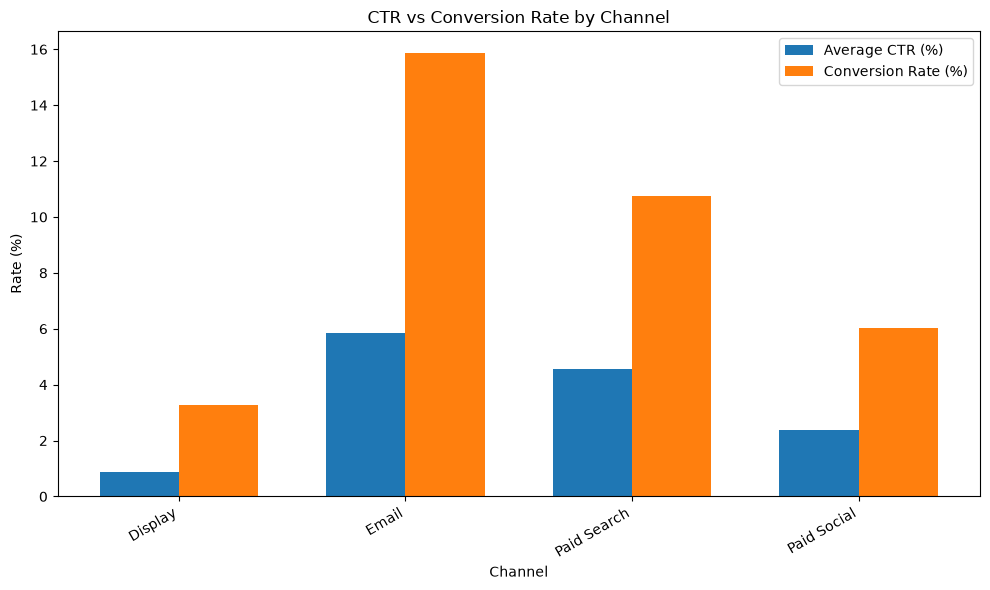

In [9]:
# ctr vs cvr by channel

x = range(len(scatter_data))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    [i - width / 2 for i in x],
    scatter_data['avg_ctr'],
    width,
    label='Average CTR (%)'
)

ax.bar(
    [i + width / 2 for i in x],
    scatter_data['cvr'],
    width,
    label='Conversion Rate (%)'
)

ax.set_title('CTR vs Conversion Rate by Channel')
ax.set_xlabel('Channel')
ax.set_ylabel('Rate (%)')
ax.set_xticks(list(x))
ax.set_xticklabels(scatter_data['channel'], rotation=30, ha='right')
ax.legend()

plt.tight_layout()
plt.show()

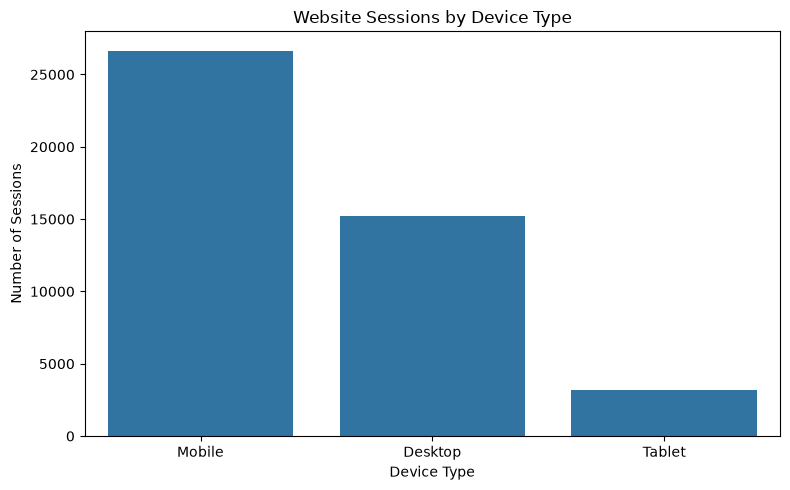

In [10]:
# session distribution by device type

device_counts = sessions['device_type'].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=device_counts.index,
    y=device_counts.values
)

plt.title('Website Sessions by Device Type')
plt.xlabel('Device Type')
plt.ylabel('Number of Sessions')

plt.tight_layout()
plt.show()

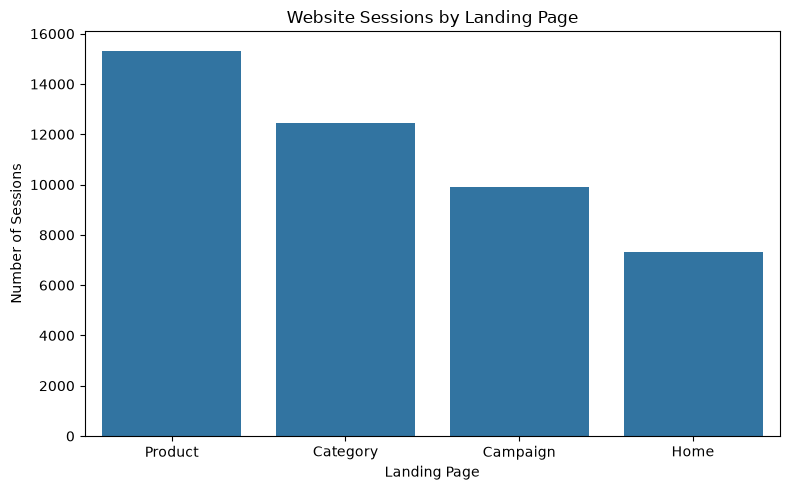

In [11]:
# session distribution by landing page

landing_counts = sessions['landing_page'].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=landing_counts.index,
    y=landing_counts.values
)

plt.title('Website Sessions by Landing Page')
plt.xlabel('Landing Page')
plt.ylabel('Number of Sessions')

plt.tight_layout()
plt.show()

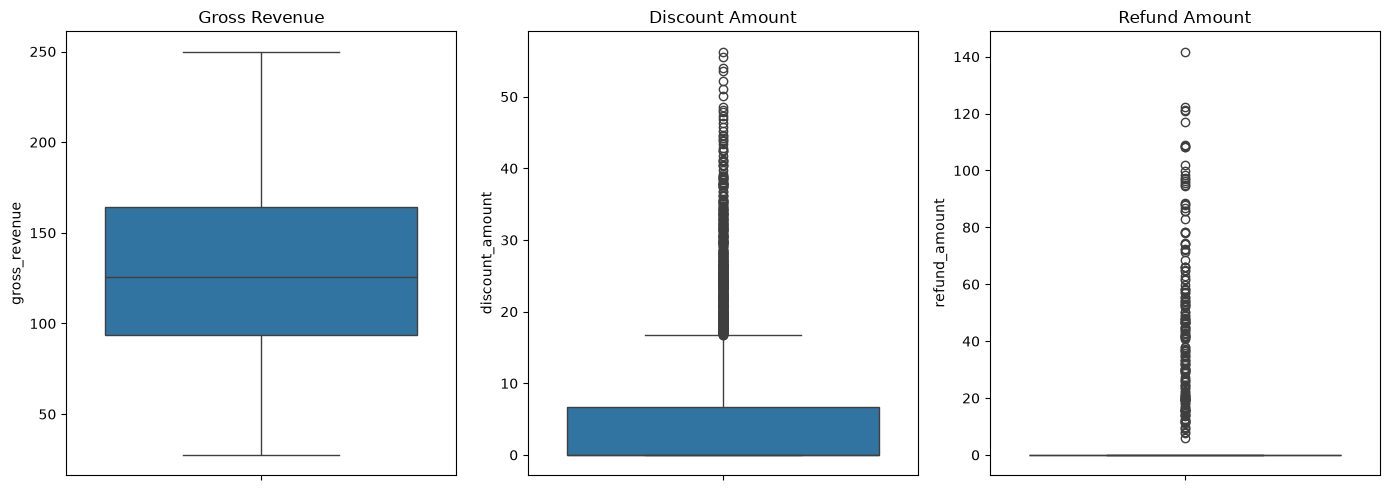

In [12]:
# outlier analysis

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

sns.boxplot(y=orders['gross_revenue'], ax=axes[0])
axes[0].set_title('Gross Revenue')

sns.boxplot(y=orders['discount_amount'], ax=axes[1])
axes[1].set_title('Discount Amount')

sns.boxplot(y=orders['refund_amount'], ax=axes[2])
axes[2].set_title('Refund Amount')

plt.tight_layout()
plt.show()

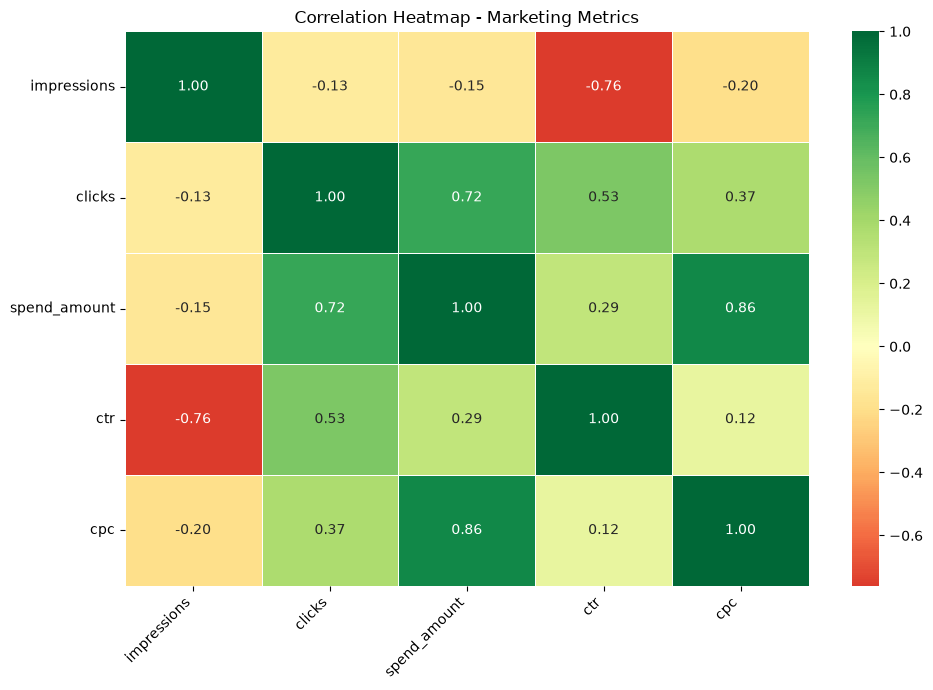

In [14]:
# join campaigns and marketing spend

campaign_data = marketing_spend.merge(
    campaigns,
    on='campaign_id',
    how='left'
)

# select numerical columns

numeric_data = campaign_data.select_dtypes(include='number').drop(
    columns=['campaign_id'],
    errors='ignore'
)

# correlation heatmap

corr_matrix = numeric_data.corr().round(2)

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn',
    center=0,
    linewidths=0.5,
    linecolor='white'
)

plt.title('Correlation Heatmap - Marketing Metrics')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()